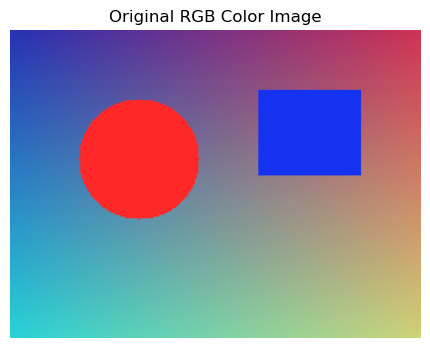

Case 1: Mean Average of RGB Planes


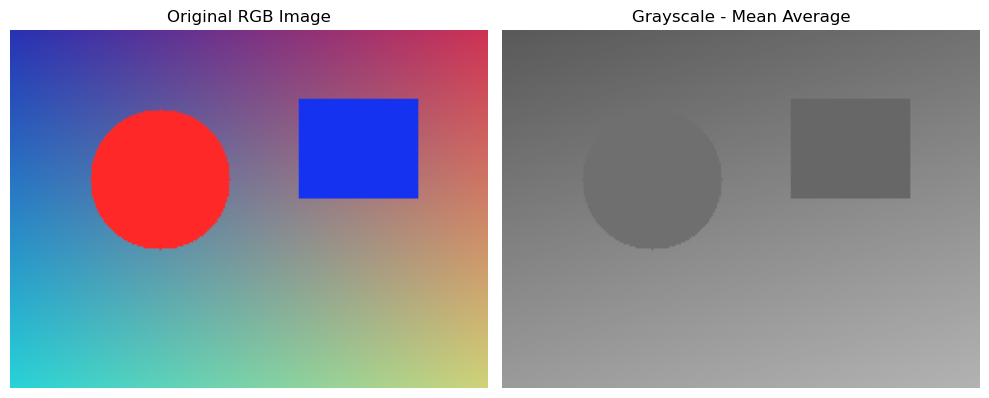

Enter RGB weights (their sum must equal 1)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a sample RGB color image
height, width = 180, 240
y, x = np.mgrid[0:height, 0:width]

R = np.clip(40 + x * 0.7, 0, 255)
G = np.clip(50 + y * 0.9, 0, 255)
B = np.clip(180 - x * 0.4 + y * 0.2, 0, 255)

rgb_image = np.stack([R, G, B], axis=2).astype(np.uint8)

# Add colored shapes
yy, xx = np.ogrid[:height, :width]

rgb_image[(xx-75)**2 + (yy-75)**2 <= 35**2] = [255, 40, 40]
rgb_image[35:85, 145:205] = [20, 50, 240]

# Display original RGB image
plt.figure(figsize=(6, 4))
plt.imshow(rgb_image)
plt.title("Original RGB Color Image")
plt.axis('off')
plt.show()


# CASE 1: Mean average of three planes

R = rgb_image[:, :, 0].astype(float)
G = rgb_image[:, :, 1].astype(float)
B = rgb_image[:, :, 2].astype(float)

gray_mean = ((R + G + B) / 3).astype(np.uint8)

print("Case 1: Mean Average of RGB Planes")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original RGB Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gray_mean, cmap='gray', vmin=0, vmax=255)
plt.title("Grayscale - Mean Average")
plt.axis('off')

plt.tight_layout()
plt.show()


# CASE 2: User-defined weights

print("Enter RGB weights (their sum must equal 1)")

wR = float(input("Enter weight of Red: "))
wG = float(input("Enter weight of Green: "))
wB = float(input("Enter weight of Blue: "))

if (any(w < 0 or w > 1 for w in [wR, wG, wB])
        or not np.isclose(wR + wG + wB, 1.0)):
    raise ValueError("Weights must be between 0 and 1 and sum to 1.")

gray_weighted = (
    wR * R + wG * G + wB * B
).round().clip(0, 255).astype(np.uint8)

print("Case 2: Weighted Average")
print("Red Weight:", wR)
print("Green Weight:", wG)
print("Blue Weight:", wB)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original RGB Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gray_weighted, cmap='gray', vmin=0, vmax=255)
plt.title("Grayscale - Weighted Average")
plt.axis('off')

plt.tight_layout()
plt.show()
